# Peningkatan Kontras Citra dengan CLAHE

Pengolahan Citra Digital


## Tujuan

Membandingkan Global Histogram Equalization (GHE) dengan CLAHE pada tiga jenis citra yang kontrasnya bermasalah: rontgen dada, foto bawah laut, dan jalan pada malam hari. Setelah itu dilihat juga bagaimana `clipLimit` dan `tileGridSize` memengaruhi hasil CLAHE.

## Dasar teori

GHE memetakan intensitas $r_k$ ke $s_k$ lewat CDF histogram seluruh citra:

$$s_k = (L-1)\sum_{j=0}^{k} p(r_j), \quad p(r_j) = \frac{n_j}{MN}$$

Karena satu fungsi dipakai untuk seluruh citra, wilayah yang luas dan seragam (misalnya langit malam) ikut diregangkan dan noise-nya terangkat.

CLAHE (Zuiderveld, 1994) bekerja per blok:
1. Citra dibagi menjadi kisi `tileGridSize`, tiap blok punya histogram sendiri.
2. Histogram dipotong pada `clipLimit`, kelebihannya dibagi rata ke semua bin, sehingga kenaikan kontras terbatas.
3. Hasil antar blok digabung dengan interpolasi bilinear supaya batas blok tidak terlihat.

Untuk citra berwarna, ekualisasi tidak dilakukan per kanal RGB karena warna bisa bergeser. Citra diubah ke CIE L\*a\*b\*, lalu hanya kanal L yang diproses.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMG_DIR = "image"
plt.rcParams["figure.dpi"] = 100

print("OpenCV", cv2.__version__)

OpenCV 4.13.0


## Metrik

Tidak ada citra referensi, jadi dipakai tiga metrik tanpa referensi:

- Entropi Shannon, $H = -\sum p(i)\log_2 p(i)$
- Standar deviasi intensitas sebagai ukuran kontras
- AMBE, $|\mu_{out} - \mu_{in}|$, selisih rata-rata kecerahan

Ketiganya tidak menggantikan penilaian visual. Entropi dan standar deviasi bisa naik karena noise ikut terangkat.

In [2]:
def entropy(g):
    h = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel()
    p = h / h.sum()
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def hitung(asli, hasil, nama):
    return {"metode": nama,
            "entropi": entropy(hasil),
            "std": hasil.std(),
            "ambe": abs(hasil.mean() - asli.mean())}

def lab_l(bgr):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    return lab, lab[:, :, 0]

def kembali_bgr(lab, l_baru):
    lab2 = lab.copy()
    lab2[:, :, 0] = l_baru
    return cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)

def tampilkan(tiga, judul, gray_l):
    # tiga: [asli, ghe, clahe]; gray_l: [L asli, L ghe, L clahe] untuk histogram
    nama = ["Asli", "GHE", "CLAHE"]
    fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
    for i in range(3):
        if tiga[i].ndim == 2:
            ax[0, i].imshow(tiga[i], cmap="gray", vmin=0, vmax=255)
        else:
            ax[0, i].imshow(cv2.cvtColor(tiga[i], cv2.COLOR_BGR2RGB))
        ax[0, i].set_title(nama[i])
        ax[0, i].axis("off")
        ax[1, i].hist(gray_l[i].ravel(), bins=256, range=(0, 255), color="gray")
        ax[1, i].set_xlim(0, 255)
        ax[1, i].set_xlabel("intensitas")
    ax[1, 0].set_ylabel("jumlah piksel")
    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()

hasil = []   # menampung metrik semua eksperimen untuk tabel akhir

## Eksperimen 1: rontgen dada

Citra dibaca sebagai grayscale. CLAHE memakai `clipLimit=2.0` dan grid 8x8.

(1956, 2412)


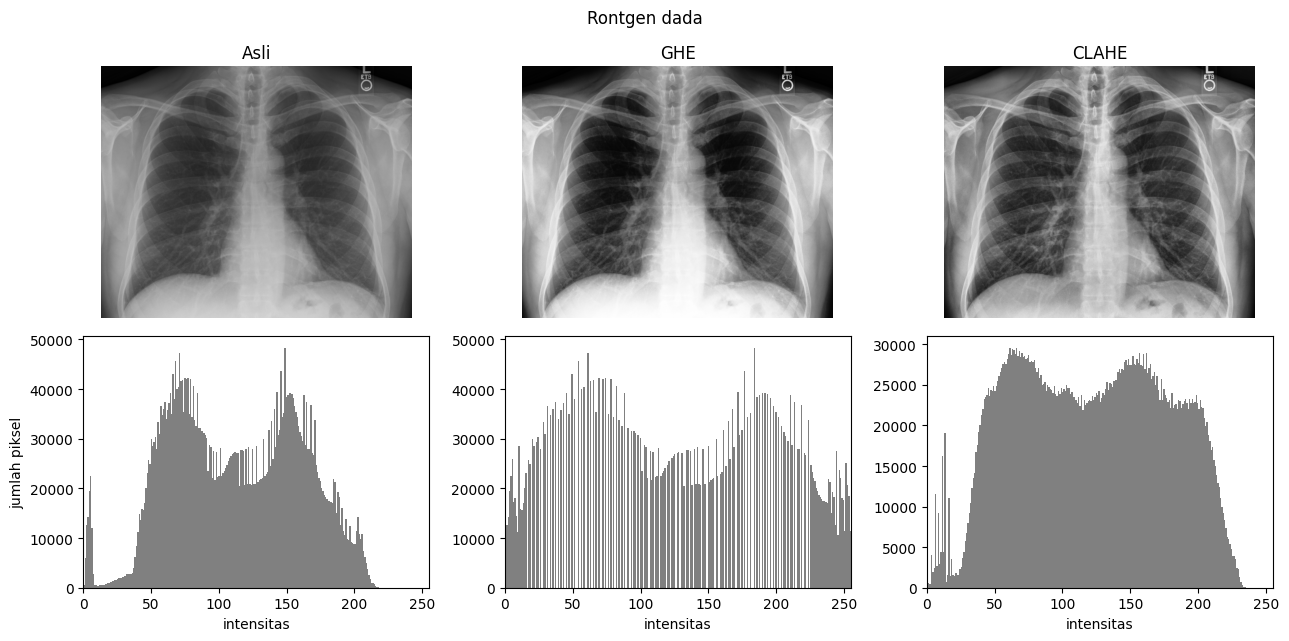

,citra,metode,entropi,std,ambe
0,Rontgen dada,Asli,7.43,47.75,0.00
1,Rontgen dada,GHE,7.34,73.55,15.12
2,Rontgen dada,CLAHE,7.68,55.13,7.65


In [3]:
xray = cv2.imread(os.path.join(IMG_DIR, "Chest_Xray_PA_3-8-2010.png"), cv2.IMREAD_GRAYSCALE)
print(xray.shape)

xray_ghe = cv2.equalizeHist(xray)
xray_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(xray)

tampilkan([xray, xray_ghe, xray_clahe], "Rontgen dada", [xray, xray_ghe, xray_clahe])

tab1 = pd.DataFrame([hitung(xray, xray, "Asli"),
                     hitung(xray, xray_ghe, "GHE"),
                     hitung(xray, xray_clahe, "CLAHE")]).round(2)
tab1.insert(0, "citra", "Rontgen dada")
hasil.append(tab1)
tab1

Pengamatan: GHE menaikkan std dari 47.75 ke 73.55, tetapi entropinya justru turun (7.43 ke 7.34). Mediastinum dan area di bawah diafragma jadi sangat terang, dan histogramnya berbentuk sisir karena banyak level intensitas yang kosong. CLAHE menaikkan entropi ke 7.68 dengan AMBE 7.65, sekitar setengah dari GHE (15.12). Corak pembuluh dan tulang rusuk di paru lebih jelas dibanding citra asli tanpa area yang terlalu terang seperti pada GHE.

Citra ini hampir tidak punya latar hitam (hanya pojok atas), jadi soal noise di latar dicek terpisah di bawah.

## Eksperimen 2: bawah laut

Citra berwarna, jadi ekualisasi hanya pada kanal L. Untuk citra ini `clipLimit=2.5`, nilainya dipilih dari beberapa percobaan.

(3072, 2304, 3)


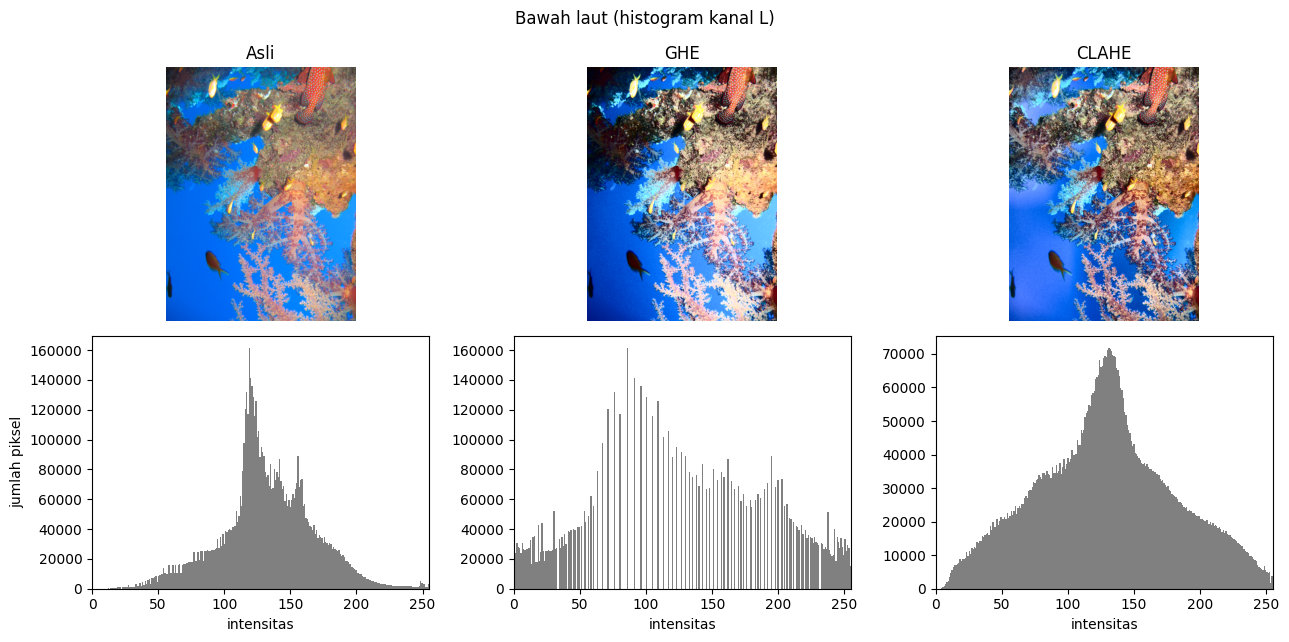

,citra,metode,entropi,std,ambe
0,Bawah laut,Asli,7.12,35.45,0.00
1,Bawah laut,GHE,6.91,73.51,3.76
2,Bawah laut,CLAHE,7.70,52.11,3.56


In [4]:
coral = cv2.imread(os.path.join(IMG_DIR, "Red_sea_underwater_coral.jpg"))
print(coral.shape)

lab_c, l_c = lab_l(coral)
l_c_ghe = cv2.equalizeHist(l_c)
l_c_clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(l_c)

coral_ghe = kembali_bgr(lab_c, l_c_ghe)
coral_clahe = kembali_bgr(lab_c, l_c_clahe)

tampilkan([coral, coral_ghe, coral_clahe], "Bawah laut (histogram kanal L)", [l_c, l_c_ghe, l_c_clahe])

tab2 = pd.DataFrame([hitung(l_c, l_c, "Asli"),
                     hitung(l_c, l_c_ghe, "GHE"),
                     hitung(l_c, l_c_clahe, "CLAHE")]).round(2)
tab2.insert(0, "citra", "Bawah laut")
hasil.append(tab2)
tab2

Pengamatan: GHE membuat air menjadi biru pekat dan warna tampak terlalu jenuh; entropinya turun dari 7.11 ke 6.91 walau std naik dua kali lipat. CLAHE menaikkan entropi ke 7.69, dan tekstur serta cabang karang lebih terlihat. Kekurangannya, air di latar jadi lebih pucat karena L dinaikkan sementara a* dan b* tidak diubah. Warna tidak bergeser, tetapi kesan pudar muncul. AMBE kedua metode hampir sama (3.62 dan 3.33).

## Eksperimen 3: jalan malam hari

Prosedurnya sama dengan eksperimen 2, dengan `clipLimit=3.0` karena sebagian besar citra sangat gelap.

(2448, 3264, 3)


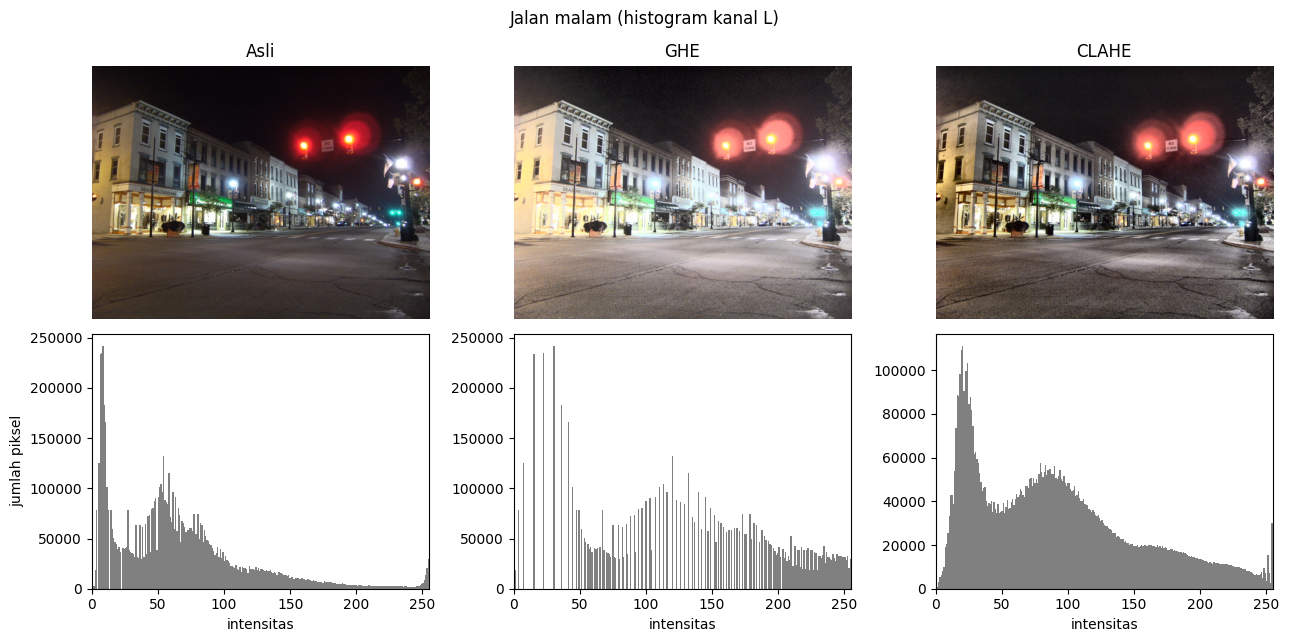

,citra,metode,entropi,std,ambe
0,Jalan malam,Asli,7.17,51.45,0.00
1,Jalan malam,GHE,6.92,72.86,63.30
2,Jalan malam,CLAHE,7.68,61.63,25.36


In [5]:
night = cv2.imread(os.path.join(IMG_DIR, "Night_Street_with_Stoplights.jpg"))
print(night.shape)

lab_n, l_n = lab_l(night)
l_n_ghe = cv2.equalizeHist(l_n)
l_n_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(l_n)

night_ghe = kembali_bgr(lab_n, l_n_ghe)
night_clahe = kembali_bgr(lab_n, l_n_clahe)

tampilkan([night, night_ghe, night_clahe], "Jalan malam (histogram kanal L)", [l_n, l_n_ghe, l_n_clahe])

tab3 = pd.DataFrame([hitung(l_n, l_n, "Asli"),
                     hitung(l_n, l_n_ghe, "GHE"),
                     hitung(l_n, l_n_clahe, "CLAHE")]).round(2)
tab3.insert(0, "citra", "Jalan malam")
hasil.append(tab3)
tab3

Pengamatan: GHE menaikkan kecerahan rata-rata terlalu jauh (AMBE 63.32). Jalan dan fasad bangunan tampak berkabut, bintik noise terlihat di langit, dan cahaya lampu lalu lintas melebar. CLAHE lebih terkendali (AMBE 25.05); fasad, marka, dan aspal terlihat lebih jelas. Halo di sekitar lampu merah tetap terlihat pada CLAHE, jadi sorotan lampu tidak sepenuhnya tertangani.

Untuk citra gelap seperti ini AMBE yang kecil tidak otomatis lebih baik, karena tujuannya memang mencerahkan.

## Cek noise pada area homogen

Untuk mengecek apakah noise di area seragam benar naik, diambil satu patch gelap di pojok kiri atas rontgen dan satu patch langit pada citra malam. Nilai yang dilihat adalah rata-rata dan standar deviasi di dalam patch.

In [6]:
patch_xray = (slice(0, 120), slice(0, 250))
patch_langit = (slice(0, 250), slice(900, 1700))

def stat_patch(img, sl, nama):
    p = img[sl]
    return {"patch": nama, "rata-rata": p.mean(), "std": p.std()}

baris = []
for nama, gambar in [("Asli", xray), ("GHE", xray_ghe), ("CLAHE", xray_clahe)]:
    baris.append({"citra": "Rontgen (pojok)", "metode": nama, **stat_patch(gambar, patch_xray, "")})
for nama, gambar in [("Asli", l_n), ("GHE", l_n_ghe), ("CLAHE", l_n_clahe)]:
    baris.append({"citra": "Malam (langit)", "metode": nama, **stat_patch(gambar, patch_langit, "")})

pd.DataFrame(baris).drop(columns="patch").round(2)

,citra,metode,rata-rata,std
0,Rontgen (pojok),Asli,4.80,2.90
1,Rontgen (pojok),GHE,3.45,1.21
2,Rontgen (pojok),CLAHE,12.30,4.49
3,Malam (langit),Asli,5.35,1.81
4,Malam (langit),GHE,12.85,9.31
5,Malam (langit),CLAHE,17.88,5.79


Pada rontgen, dugaan bahwa GHE memperkuat noise di latar gelap tidak terbukti. Di pojok atas GHE justru menurunkan std (2.90 ke 1.21), sedangkan CLAHE menaikkan rata-rata (4.80 ke 12.30) dan std (4.49). Kemungkinan karena CLAHE meregangkan blok pojok yang hampir seluruhnya gelap, tapi ini belum diuji.

Pada citra malam hasilnya sesuai dugaan: std langit naik dari 1.85 ke 10.13 pada GHE dan ke 5.79 pada CLAHE. Catatan: hanya satu patch per citra.

## Eksperimen 4: pengaruh clipLimit dan tileGridSize

Dilakukan pada citra rontgen. Pertama `clipLimit` divariasikan dengan grid 8x8, lalu grid divariasikan dengan `clipLimit=2.0`.

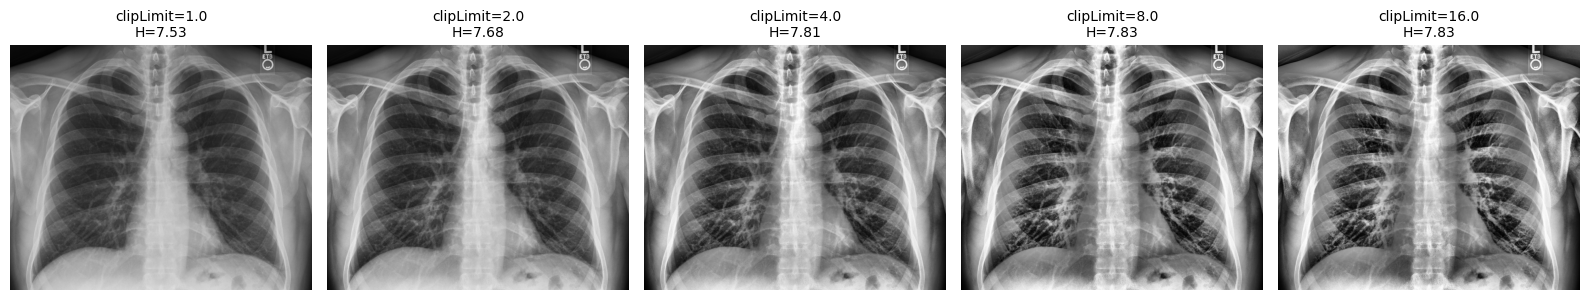

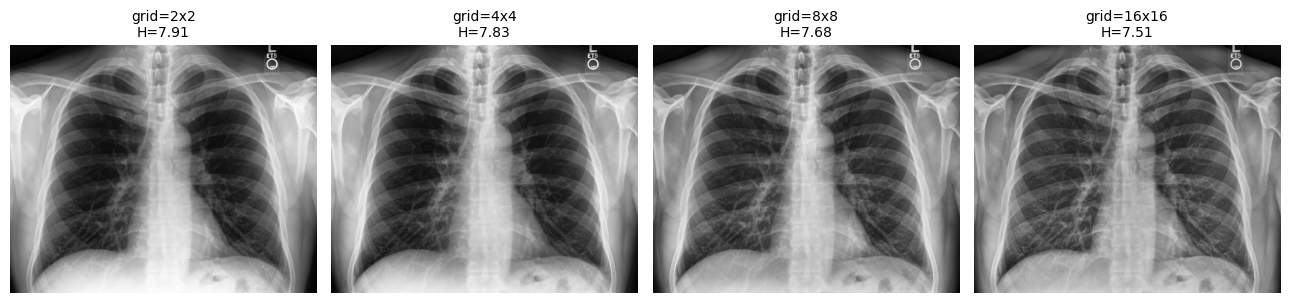

In [7]:
clips = [1.0, 2.0, 4.0, 8.0, 16.0]
grids = [(2, 2), (4, 4), (8, 8), (16, 16)]

res_clip = [cv2.createCLAHE(clipLimit=c, tileGridSize=(8, 8)).apply(xray) for c in clips]
res_grid = [cv2.createCLAHE(clipLimit=2.0, tileGridSize=g).apply(xray) for g in grids]

fig, ax = plt.subplots(1, 5, figsize=(16, 3.8))
for a, r, c in zip(ax, res_clip, clips):
    a.imshow(r, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"clipLimit={c}\nH={entropy(r):.2f}", fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(13, 3.8))
for a, r, g in zip(ax, res_grid, grids):
    a.imshow(r, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"grid={g[0]}x{g[1]}\nH={entropy(r):.2f}", fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.show()

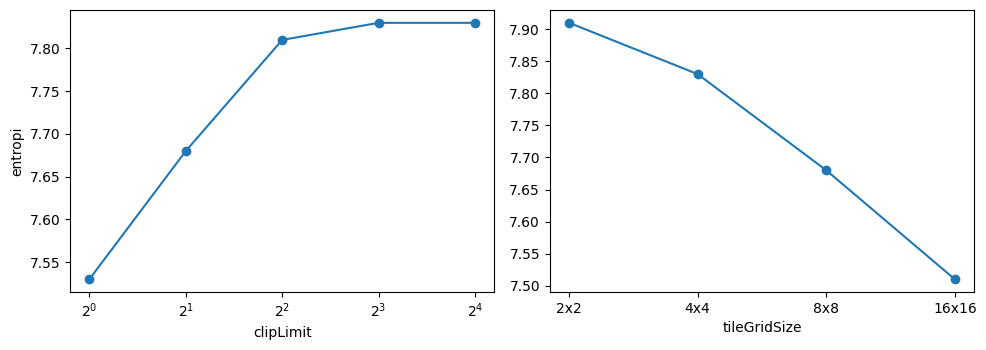

 clipLimit  entropi   std  ambe
       1.0     7.53 51.73  4.58
       2.0     7.68 55.13  7.65
       4.0     7.81 57.62 10.57
       8.0     7.83 58.43 14.05
      16.0     7.83 58.21 15.90

 grid  entropi   std  ambe
  2x2     7.91 70.02 12.09
  4x4     7.83 65.93 10.72
  8x8     7.68 55.13  7.65
16x16     7.51 48.09  5.97


In [8]:
tab_clip = pd.DataFrame({"clipLimit": clips,
                         "entropi": [entropy(r) for r in res_clip],
                         "std": [r.std() for r in res_clip],
                         "ambe": [abs(r.mean() - xray.mean()) for r in res_clip]}).round(2)
tab_grid = pd.DataFrame({"grid": [f"{g[0]}x{g[1]}" for g in grids],
                         "entropi": [entropy(r) for r in res_grid],
                         "std": [r.std() for r in res_grid],
                         "ambe": [abs(r.mean() - xray.mean()) for r in res_grid]}).round(2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(clips, tab_clip["entropi"], "o-")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("clipLimit")
ax[0].set_ylabel("entropi")
ax[1].plot(tab_grid["grid"], tab_grid["entropi"], "o-")
ax[1].set_xlabel("tileGridSize")
plt.tight_layout()
plt.show()

print(tab_clip.to_string(index=False))
print()
print(tab_grid.to_string(index=False))

clipLimit: entropi naik dari 7.53 (1.0) ke 7.83 (8.0), lalu datar di 16.0, sementara AMBE terus naik (4.58 sampai 15.90). Pada clipLimit 8 ke atas paru-paru terlihat kasar dan mediastinum terlalu terang, jadi kenaikan entropi di atas 4 tidak sebanding dengan perubahan tampilan.

tileGridSize: hasilnya berlawanan dengan dugaan awal. Entropi dan std turun saat grid makin rapat (7.91 pada 2x2 menjadi 7.51 pada 16x16). Grid 2x2 memberi angka tertinggi, tetapi secara visual paling mirip GHE. Jadi 8x8 dipilih sebagai kompromi, bukan karena optimum menurut metrik. Pengujian ini hanya pada satu citra.

## Rekapitulasi

In [9]:
rekap = pd.concat(hasil, ignore_index=True)
rekap.columns = ["citra", "metode", "entropi", "std", "ambe"]
rekap

,citra,metode,entropi,std,ambe
0,Rontgen dada,Asli,7.43,47.75,0.00
1,Rontgen dada,GHE,7.34,73.55,15.12
2,Rontgen dada,CLAHE,7.68,55.13,7.65
3,Bawah laut,Asli,7.12,35.45,0.00
4,Bawah laut,GHE,6.91,73.51,3.76
5,Bawah laut,CLAHE,7.70,52.11,3.56
6,Jalan malam,Asli,7.17,51.45,0.00
7,Jalan malam,GHE,6.92,72.86,63.30
8,Jalan malam,CLAHE,7.68,61.63,25.36


## Kesimpulan

- CLAHE menaikkan entropi pada ketiga citra (7.43 ke 7.68, 7.11 ke 7.69, 7.16 ke 7.67), sedangkan GHE menurunkannya meskipun std-nya naik lebih besar.
- Perubahan kecerahan rata-rata CLAHE lebih kecil daripada GHE pada semua citra (AMBE 7.65 vs 15.12, 3.33 vs 3.62, 25.05 vs 63.32).
- CLAHE menekan noise di langit citra malam, tetapi tidak di pojok gelap rontgen, jadi CLAHE tidak selalu menjaga latar tetap bersih.
- Pada citra berwarna, memproses kanal L menjaga hue, tetapi area biru yang seragam di foto bawah laut menjadi lebih pucat.
- Nilai `clipLimit` 2 sampai 3 dan grid 8x8 cukup wajar sebagai titik awal. Metrik saja tidak cukup untuk memilih parameter, hasil visual tetap perlu dilihat.

Keterbatasan: hanya satu citra per domain, metrik tanpa referensi, dan tidak ada penilaian dari ahli untuk citra medis.